<a href="https://colab.research.google.com/github/alokganesh2007-netizen/EDA-expolatory-data-analysis/blob/main/Alok_Gupta_EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

print("All libraries imported successfully!")

All libraries imported successfully!


# 1. Introduction and Data Loading
## 1.1 Loading the Dataset

In [ ]:
df = pd.read_csv('/content/Train Data.csv')

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [ ]:
# Check the number of rows and columns

print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

Number of Rows: 1460
Number of Columns: 81


In [ ]:
# Display first 5 rows

df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [ ]:
# Information about dataset

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

In [ ]:
# Count missing values in each column

missing = df.isnull().sum()

missing = missing[missing > 0].sort_values(ascending=False)

print("Columns containing missing values:")
print(missing)

Columns containing missing values:
PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
GarageCond        81
BsmtExposure      38
BsmtFinType2      38
BsmtQual          37
BsmtCond          37
BsmtFinType1      37
MasVnrArea         8
Electrical         1
dtype: int64


In [ ]:
# Calculate missing value percentages

missing_percentage = (df.isnull().sum() / len(df)) * 100

missing_percentage = missing_percentage[missing_percentage > 0]
missing_percentage = missing_percentage.sort_values(ascending=False)

print(missing_percentage.round(2))

PoolQC          99.52
MiscFeature     96.30
Alley           93.77
Fence           80.75
MasVnrType      59.73
FireplaceQu     47.26
LotFrontage     17.74
GarageType       5.55
GarageYrBlt      5.55
GarageFinish     5.55
GarageQual       5.55
GarageCond       5.55
BsmtExposure     2.60
BsmtFinType2     2.60
BsmtQual         2.53
BsmtCond         2.53
BsmtFinType1     2.53
MasVnrArea       0.55
Electrical       0.07
dtype: float64


## 2. Data Understanding

### 2.1 Classification of Variables

In [ ]:
# Identify numerical and categorical columns

numeric_cols = df.select_dtypes(include=np.number).columns.tolist()

categorical_cols = df.select_dtypes(include='object').columns.tolist()

print("Total Numerical Columns:", len(numeric_cols))
print("Total Categorical Columns:", len(categorical_cols))

Total Numerical Columns: 38
Total Categorical Columns: 43


In [ ]:
# Define ordinal variables

ordinal_map = {
    "ExterQual": ["Po", "Fa", "TA", "Gd", "Ex"],
    "KitchenQual": ["Po", "Fa", "TA", "Gd", "Ex"]
}

# Convert columns into ordered categories

for column in ordinal_map:
    df[column] = pd.Categorical(
        df[column],
        categories=ordinal_map[column],
        ordered=True
    )

print("Ordinal variables successfully classified!")

Ordinal variables successfully classified!


In [ ]:
# Create variable summary

summary = pd.DataFrame({
    "Column": df.columns,
    "Data Type": df.dtypes.astype(str).values,
    "Unique Values": df.nunique().values,
    "Example Values": [
        df[col].dropna().unique()[:3].tolist()
        for col in df.columns
    ]
})

summary

,Column,Data Type,Unique Values,Example Values
0,Id,int64,1460,"[1, 2, 3]"
1,MSSubClass,int64,15,"[60, 20, 70]"
2,MSZoning,object,5,"[RL, RM, C (all)]"
3,LotFrontage,float64,110,"[65.0, 80.0, 68.0]"
4,LotArea,int64,1073,"[8450, 9600, 11250]"
...,...,...,...,...
76,MoSold,int64,12,"[2, 5, 9]"
77,YrSold,int64,5,"[2008, 2007, 2006]"
78,SaleType,object,9,"[WD, New, COD]"
79,SaleCondition,object,6,"[Normal, Abnorml, Partial]"


## 3. Descriptive Statistics

### 3.1 Statistical Summary

In [ ]:
# Display descriptive statistics

df.describe()

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


In [ ]:
# Calculate statistical measures

columns = ['SalePrice', 'GrLivArea', 'LotArea']

for col in columns:

    print("\nStatistics for:", col)

    print("Mean:", df[col].mean())
    print("Median:", df[col].median())
    print("Mode:", df[col].mode()[0])

    print("Standard Deviation:", df[col].std())
    print("Variance:", df[col].var())

    print("Range:", df[col].max() - df[col].min())

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    print("IQR:", Q3 - Q1)

    print("Skewness:", df[col].skew())
    print("Kurtosis:", df[col].kurt())


Statistics for: SalePrice
Mean: 180921.19589041095
Median: 163000.0
Mode: 140000
Standard Deviation: 79442.50288288663
Variance: 6311111264.297451
Range: 720100
IQR: 84025.0
Skewness: 1.8828757597682129
Kurtosis: 6.536281860064529

Statistics for: GrLivArea
Mean: 1515.463698630137
Median: 1464.0
Mode: 864
Standard Deviation: 525.4803834232027
Variance: 276129.63336259616
Range: 5308
IQR: 647.25
Skewness: 1.3665603560164552
Kurtosis: 4.895120580693174

Statistics for: LotArea
Mean: 10516.828082191782
Median: 9478.5
Mode: 7200
Standard Deviation: 9981.264932379147
Variance: 99625649.6503417
Range: 213945
IQR: 4048.0
Skewness: 12.207687851233496
Kurtosis: 203.24327101886033


In [ ]:
# Frequency distribution of categorical variables

print("Neighborhood Frequency:")
print(df['Neighborhood'].value_counts())

print("\nHouse Style Frequency:")
print(df['HouseStyle'].value_counts())

Neighborhood Frequency:
Neighborhood
NAmes      225
CollgCr    150
OldTown    113
Edwards    100
Somerst     86
Gilbert     79
NridgHt     77
Sawyer      74
NWAmes      73
SawyerW     59
BrkSide     58
Crawfor     51
Mitchel     49
NoRidge     41
Timber      38
IDOTRR      37
ClearCr     28
SWISU       25
StoneBr     25
Blmngtn     17
MeadowV     17
BrDale      16
Veenker     11
NPkVill      9
Blueste      2
Name: count, dtype: int64

House Style Frequency:
HouseStyle
1Story    726
2Story    445
1.5Fin    154
SLvl       65
SFoyer     37
1.5Unf     14
2.5Unf     11
2.5Fin      8
Name: count, dtype: int64


## 4. Data Visualization

### 4.1 Distribution of Numerical Variables

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

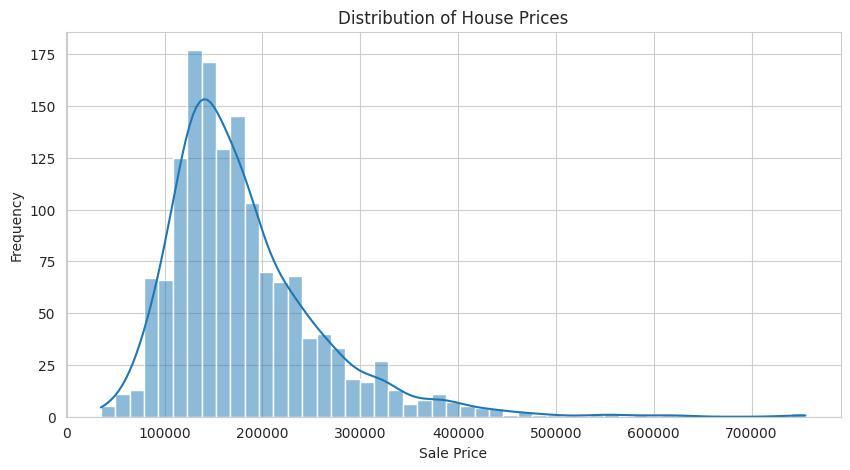

In [ ]:
plt.figure(figsize=(10,5))

sns.histplot(df['SalePrice'], kde=True)

plt.title('Distribution of House Prices')
plt.xlabel('Sale Price')
plt.ylabel('Frequency')

plt.show()

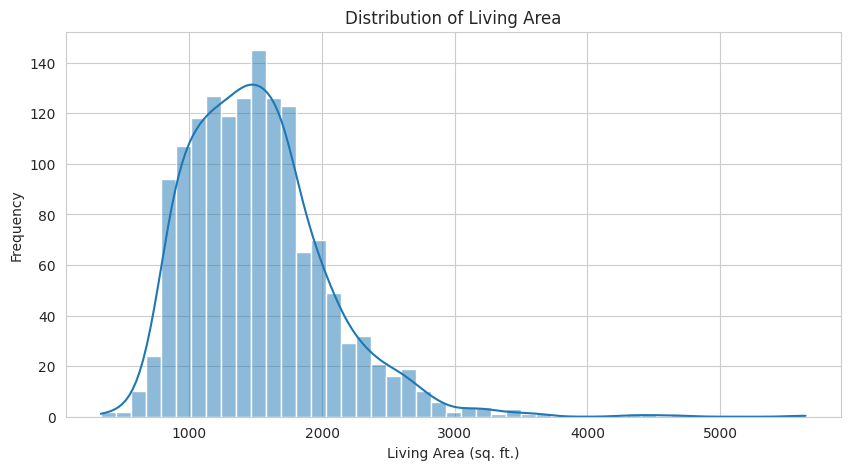

In [ ]:
plt.figure(figsize=(10,5))

sns.histplot(df['GrLivArea'], kde=True)

plt.title('Distribution of Living Area')
plt.xlabel('Living Area (sq. ft.)')
plt.ylabel('Frequency')

plt.show()

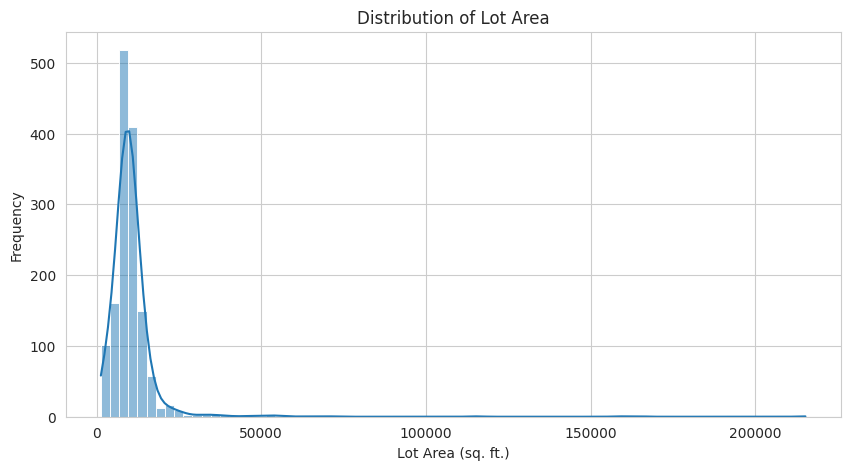

In [ ]:
plt.figure(figsize=(10,5))

sns.histplot(df['LotArea'], kde=True)

plt.title('Distribution of Lot Area')
plt.xlabel('Lot Area (sq. ft.)')
plt.ylabel('Frequency')

plt.show()

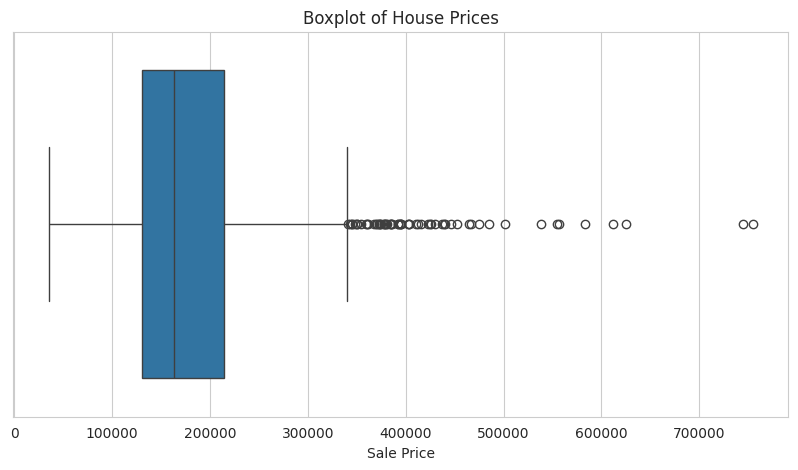

In [ ]:
plt.figure(figsize=(10,5))

sns.boxplot(x=df['SalePrice'])

plt.title('Boxplot of House Prices')
plt.xlabel('Sale Price')

plt.show()

Observations from Data Visualization

1. SalePrice: The distribution is positively skewed, indicating that most houses are concentrated in the lower-to-middle price range, while a few houses have significantly higher prices.
2. GrLivArea: Most houses have a living area between approximately 1,000 and 2,000 square feet. A few properties have unusually large living areas.
3. LotArea: The distribution is highly positively skewed because a small number of properties have exceptionally large land areas.
4. Boxplot: The boxplot helps identify potential outliers in house prices. These observations require further investigation before deciding how to handle them.

## 5. Outlier Detection and Treatment

### 5.1 Detecting Outliers Using IQR Method

In [ ]:
# Detect outliers using IQR method

columns = ['SalePrice', 'GrLivArea', 'LotArea']

for col in columns:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_limit) |
        (df[col] > upper_limit)
    ]

    print("\nColumn:", col)
    print("Lower Limit:", lower_limit)
    print("Upper Limit:", upper_limit)
    print("Number of Outliers:", len(outliers))


Column: SalePrice
Lower Limit: 3937.5
Upper Limit: 340037.5
Number of Outliers: 61

Column: GrLivArea
Lower Limit: 158.625
Upper Limit: 2747.625
Number of Outliers: 31

Column: LotArea
Lower Limit: 1481.5
Upper Limit: 17673.5
Number of Outliers: 69


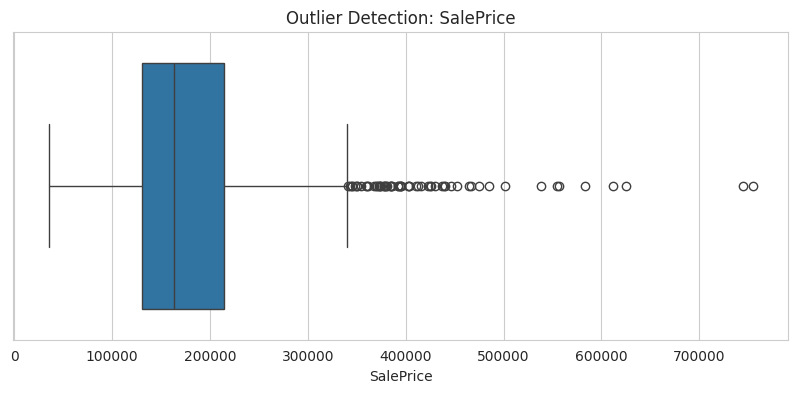

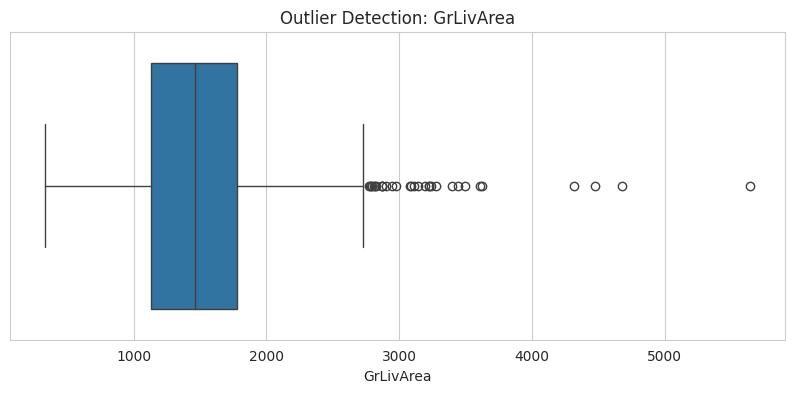

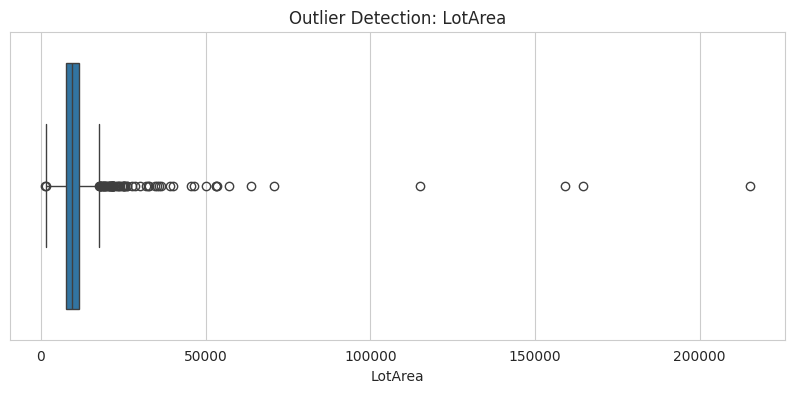

In [ ]:
# Visualize outliers using boxplots

for col in ['SalePrice', 'GrLivArea', 'LotArea']:

    plt.figure(figsize=(10, 4))

    sns.boxplot(x=df[col])

    plt.title('Outlier Detection: ' + col)

    plt.show()

Observations:

The IQR method was used to identify potential outliers in SalePrice, GrLivArea and LotArea.

Boxplots were created to visualize the distribution and identify extreme observations.

Some properties may have unusually high prices, large living areas or large land areas.

These observations will require further investigation before deciding whether they should be removed, retained or transformed.